In [16]:
import numpy as np
from qutip import *
import matplotlib.pyplot as plt

The parameters and molecualr states and the Hamiltonian is defined in the following cell.

In [17]:
au2ev = 27.21139613178773
Nb = 9

h = 1
N1 = Nb + 1
N2 = Nb + 1
el = 3
p1 = 2
p2 = 2

dim = [N1,N2,el,p1,p2]

wp = 0.003   # phonon frequency assumed to be constant
wa = 7.0/au2ev   # atom frequency
wc = 6.85/au2ev   # cavity frequency

g  = 0.05 * wc   # coupling between cavity and atom
kap = 0.0066  # vibronic coupling

def operator(local_operator,slot):
    operator = [qeye(d) for d in dim]
    operator[slot] = local_operator
    return tensor(operator)

#Non interaction terms
bl1 = destroy(N1)
bl2 = destroy(N2)

al1 = destroy(p1)
al2 = destroy(p2)

A_  = basis(el, 0)
Ep_ = basis(el, 1)
Em_ = basis(el, 2)

sig_Ep_A_l  = Ep_ * A_.dag()    #|E+><A|
sig_Em_A_l  = Em_ * A_.dag()    #|E-><A|
sig_Em_Ep_l = Em_ * Ep_.dag()   #|E-><E+|

proj_Ep_l = Ep_ * Ep_.dag()
proj_Em_l = Em_ * Em_.dag()

b1 = operator(bl1,0)
b2 = operator(bl2,1)
a1 = operator(al1,3)
a2 = operator(al2,4)

sig_Ep_A = operator(sig_Ep_A_l,2)
sig_Em_A = operator(sig_Em_A_l,2)
sig_Em_Ep = operator(sig_Em_Ep_l,2)

proj_Ep = operator(proj_Ep_l, 2) 
proj_Em = operator(proj_Em_l, 2) 

I_full = tensor([qeye(d) for d in dim])  

Hni =  h*wp*( b1.dag()*b1 + b2.dag()*b2 ) + h*wa*( proj_Ep + proj_Em ) + h*wc*( a1.dag()*a1 + a2.dag()*a2 )

Hi = g * ( a1.dag()*sig_Ep_A.dag() + a1*sig_Ep_A + a2.dag()*sig_Em_A.dag() + a2*sig_Em_A ) + kap*((b2 + b1.dag() )*sig_Em_Ep + (b2.dag() + b1)*sig_Em_Ep.dag())
# Interactions # Note that when excited state goes from + to - either a vibrational phonon is absorbed or created. The simuntaneous 
# creation and absorption of phonons does not happen because the angular momentum of phonon is double that of electronic state.
H = Hni + Hi


The following cell creates the Angular momentum operatros using the defined states.

In [18]:
# Angular momentum

Lz = b1.dag()*b1 - b2.dag()*b2
Sz = proj_Ep - proj_Em
lz = a1.dag()*a1 - a2.dag()*a2

J = 2*Lz + Sz + lz

N_ex =  proj_Ep + proj_Em + a1.dag()*a1 + a2.dag()*a2 # b1.dag()*b1 + b2.dag()*b2 # Check photon modes excitation commutation in previous code

The following cell converts the Hamiltonian matrix in a readable format. The coloured pixels are the non zero elements of the Hamiltonian. The Hamiltonian is mostly sparse.

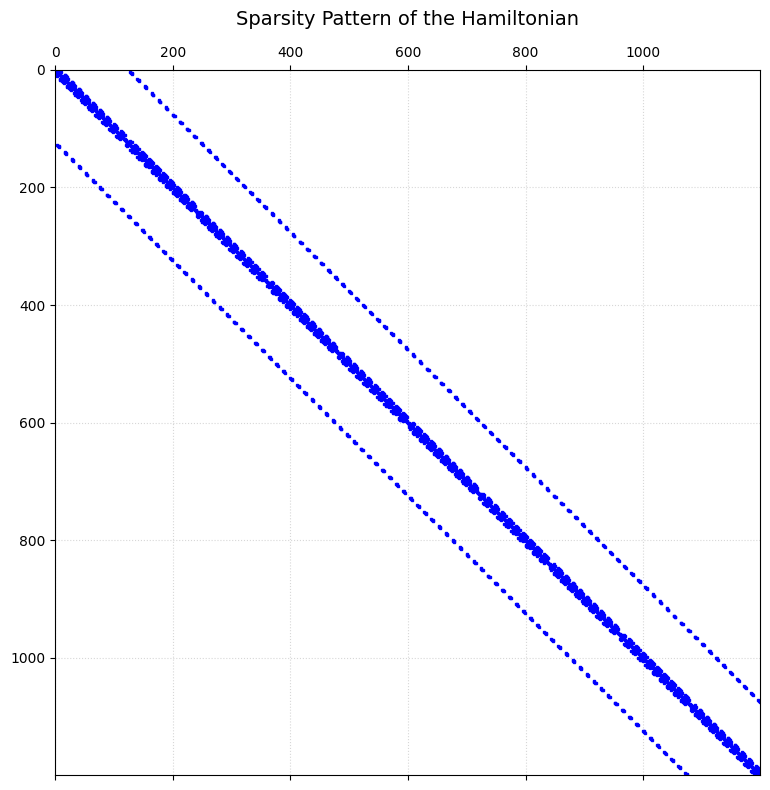

In [19]:
sparse_matrix = H.data.as_scipy()
plt.figure(figsize=(8, 8))

plt.spy(sparse_matrix, precision=0, markersize=2, color="blue")

plt.title("Sparsity Pattern of the Hamiltonian", fontsize=14, pad=15)
plt.grid(True, which="both", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

The transition dipole matrix is defined as follows.

In [20]:
d1 = 1.0
mu1 = d1 * ( sig_Em_A + sig_Em_A.dag()) # only one mode E- is taken

d2 = 1.0
mu2 = d2 * ( sig_Ep_A + sig_Ep_A.dag())

We can verify the commutation of the Hamiltonian and the Angular momentum operator through the cell.

In [21]:
Hc = H.data.as_scipy().tocsr()
Jc = J.data.as_scipy().tocsr()
print("max |[H, J]| =", abs(Hc @ Jc - Jc @ Hc).max())

max |[H, J]| = 1.1102230246251565e-16


In the following box we are taking out the block of the Hamiltonian where J = -1. As [ H , J ] = 0,
the H is present as blocks with constant J. Blocks of one J value won't interact with another. We are diagnalising this J block
to get dark and bright states. The values of transition dipole <phi|mu|G> is directly proportional to <phi|E->. 
Higher the value of E- contribution in a state, higher is the expecation of transition dipole.

In [22]:
psi_G = tensor([basis(n, 0) for n in dim])                     # Ground state
E_G   = expect(H, psi_G)

Jd     = np.real(J.diag())
g_idx  = int(np.flatnonzero(psi_G.full().ravel())[0])
sector = np.union1d(np.where(np.isclose(Jd, -1))[0], [g_idx])   # Change the J value from -1 to 1 and dipole matrix from
                                                               # mu1 to mu2 to get J = 1 Polaritons
print(len(sector))                       

Hs  = Hc[sector][:, sector].toarray()
muG = (mu1 * psi_G).full().ravel()[sector]

evals, evecs = np.linalg.eigh(Hs)

58


From the graph we can see the bright and dark states in the system. These bright states are the molecular bright states found with transition dipole matrix.

0.0


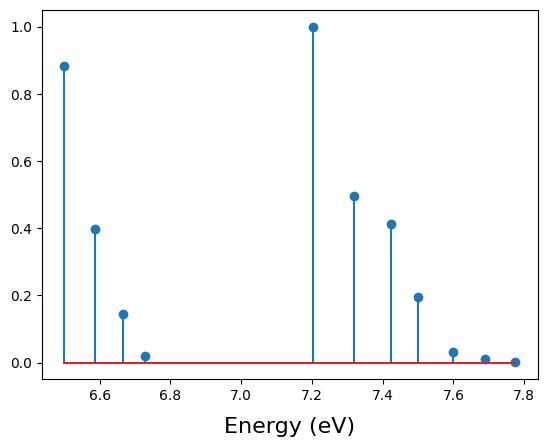

In [23]:
amp = evecs.conj().T @ muG          # <k|mu|G> Transition dipole moment value
I_k = np.abs(amp)**2

x_all  = (evals) * au2ev      # energy in eV
mask   = I_k > 1e-4                 # same cutoff as the original
x_pos  = x_all[mask]
height = I_k[mask] / I_k[mask].max()
print(E_G)
plt.xlabel('Energy (eV)', fontsize=16, labelpad=10)
plt.stem(x_pos, height)
plt.show()

Observations:
 - Observed the spectrum at different conditions.
 - Spectrum looks somewhat similar even in many vibronic mode conditions.
 - Verified for J = 1 and -1.

These bright states are the cavity bright states found with photon creation operator.

In [24]:
psi_P = tensor([basis(dim[0], 0),basis(dim[1], 0), basis(dim[2], 0), basis(dim[3], 0), basis(dim[4], 1)])                # Photon excieted state
E_G   = expect(H, psi_P)

Jd     = np.real(J.diag())
g_idx  = int(np.flatnonzero(psi_G.full().ravel())[0])
sector = np.union1d(np.where(np.isclose(Jd, -1))[0], [g_idx])   # Change the J value from -1 to 1 and dipole matrix from
                                                               # mu1 to mu2 to get J = 1 Polaritons
print(len(sector))                       

Hs  = Hc[sector][:, sector].toarray()
muP = (psi_P).full().ravel()[sector]

evals, evecs = np.linalg.eigh(Hs)

58


0.25173276544961937


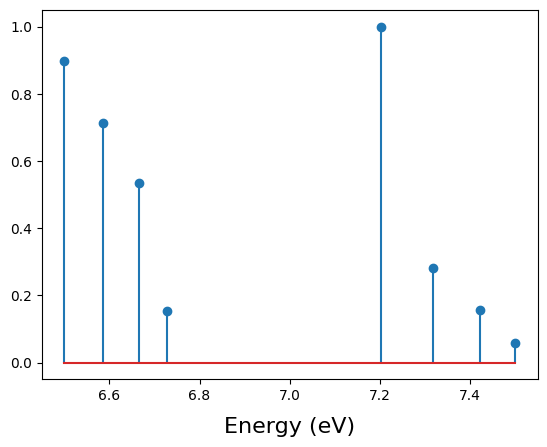

In [25]:
amp = evecs.conj().T @ muP    # Transition from photon excited to corresponding state.
I_k = np.abs(amp)**2

x_all  = (evals) * au2ev      # energy in eV
mask   = I_k > 1e-2                 # same cutoff as the original

I_kd = np.array(I_k)
x_pos  = x_all[mask]
height = I_k[mask] / I_k[mask].max()
print(E_G)
plt.xlabel('Energy (eV)', fontsize=16, labelpad=10)
plt.stem(x_pos, height)
plt.show()

<>:28: SyntaxWarning: invalid escape sequence '\g'
<>:28: SyntaxWarning: invalid escape sequence '\g'
C:\Users\haric\AppData\Local\Temp\ipykernel_23104\282652917.py:28: SyntaxWarning: invalid escape sequence '\g'
  plt.plot(x_grid, y_spectrum, 'b-', label=f'Lorentzian Spectrum ($\gamma = {gamma}$ eV)')


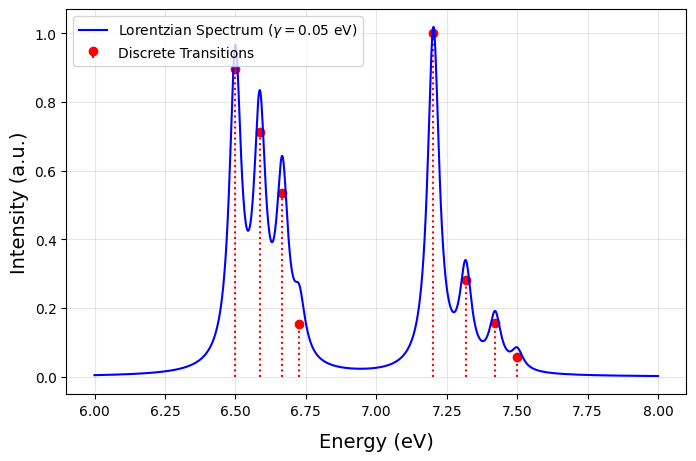

In [26]:


amp = (evecs.conj().T @ muP).flatten()   # <k|mu|G> Transition dipole moment
I_k = np.abs(amp)**2

x_all = np.array(evals).flatten() * au2ev  # energy in eV
mask  = I_k > 1e-2                        # cutoff mask

x_pos  = x_all[mask]
height = I_k[mask] / I_k[mask].max()

# Continuous energy grid
x_grid = np.linspace(x_pos.min() - 0.5, x_pos.max() + 0.5, 1000)

# Lorentzian function
# gamma: Full Width at Half Maximum (FWHM) in eV
gamma = 0.05  # Adjust gamma as needed

def lorentzian(x, x0, gamma, h):
    return h * (gamma / 2)**2 / ((x - x0)**2 + (gamma / 2)**2)

# Sum Lorentzians for all transitions
y_spectrum = np.zeros_like(x_grid)
for x0, h in zip(x_pos, height):
    y_spectrum += lorentzian(x_grid, x0, gamma, h)

# Plot stem lines and Lorentzian broadened spectrum
plt.figure(figsize=(8, 5))
plt.stem(x_pos, height, linefmt='r:', markerfmt='ro', basefmt=' ', label='Discrete Transitions')
plt.plot(x_grid, y_spectrum, 'b-', label=f'Lorentzian Spectrum ($\gamma = {gamma}$ eV)')

plt.xlabel('Energy (eV)', fontsize=14, labelpad=10)
plt.ylabel('Intensity (a.u.)', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()